# NetKet for the Long-Range Ising Model

In [2]:
import os
os.environ["JAX_PLATFORM_NAME"] = "cpu"
import netket as nk
from netket.operator.spin import sigmax, sigmaz
from scipy.sparse.linalg import eigsh
import jax
import jax.numpy as jnp
from flax import nnx
from tqdm import tqdm
import matplotlib.pyplot as plt

An NVIDIA GPU may be present on this machine, but a CUDA-enabled jaxlib is not installed. Falling back to cpu.
/home/asta/netket/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


∣NK⟩ Tip: vstate.check_mc_convergence(H) diagnoses whether your sampler is well-mixed and recommends a sweep_size.

### Define Models

`myRBM` is a custom RBM class. It seems to work very similarly to the built-in `nk.models.RBM`.
Since Models in NetKet return the logarithm of the wavefunction, a model with a real output can only ever represent non-negative wavefunctions. This restricts the learning of ground states to those of **stoquastic** Hamiltonians.
One way around this is to use complex parameters (e.g. in `nk.models.RBM`), leading to a complex output which can represent phases and negative values.
Another is to learn the modulus and phase of the wavefunction separately. This is done in `phaseRBM`,
which uses an RBM to represent the modulus and a single linear layer for the phase.
This seems to be working much better than simply using complex parameters, for some reason.

In [3]:
class myRBM(nnx.Module):
    def __init__(self, N: int, alpha: int=1, *, rngs: nnx.Rngs):
        key = rngs.params()
        self.a = nnx.Param(0.01 * jax.random.normal(rngs.params(), (N,)), dtype=float)
        nh = alpha * N
        self.b = nnx.Param(0.01 * jax.random.normal(rngs.params(), (nh,)), dtype=float)
        self.W = nnx.Param(0.01 * jax.random.normal(rngs.params(), (nh,N)), dtype=float)

    def __call__(self, x: jax.Array):
        log_amplitude = jnp.sum(self.a * x, axis=-1)
        log_amplitude += jnp.sum(jnp.log(2 * jnp.cosh( x @ self.W.T + self.b )), axis=-1) # does this work in terms of dimensions?
        return log_amplitude

class phaseRBM(nnx.Module):
    def __init__(self, N: int, alpha: int=1, *, rngs: nnx.Rngs):
        dtype = jnp.float64
        self.linear = nnx.Linear(in_features=N, out_features=N, rngs=rngs, dtype=dtype, param_dtype=dtype)

        key = rngs.params()
        self.a = nnx.Param(0.01 * jax.random.normal(rngs.params(), (N,)), dtype=dtype)
        nh = alpha * N
        self.b = nnx.Param(0.01 * jax.random.normal(rngs.params(), (nh,)), dtype=dtype)
        self.W = nnx.Param(0.01 * jax.random.normal(rngs.params(), (nh,N)), dtype=dtype)

    def __call__(self, x: jax.Array):
        log_amplitude = jnp.sum(self.a * x, axis=-1)
        # print(jnp.cosh( x @ self.W.T + self.b ).shape)
        # print(self.a.shape)
        log_amplitude += jnp.sum(jnp.log(2 * jnp.cosh( self.b + x @ self.W.T )), axis=-1) # does this work in terms of dimensions?
        phase = jnp.sum(nnx.relu(self.linear(x)), axis=-1)

        return log_amplitude + 1j * phase

### Define Main Class for (local) Ising Model
The energy expectation value can be expanded as
$$
\bra{\psi}H\ket{\psi} = \sum_s H_{ss} \left| \psi_s \right|^2 + \sum_{s\neq s'} H_{ss'} \psi_{s'}^* \psi_s
$$
(TODO: add the real part step) The diagonal elements don't care about the sign or phase of $\psi_s$.
On the other hand, if any off-diagonal element of H is positive,
the corresponding product of $\psi_{s'}^* \psi_s$ must become negative
in order to minimize the energy expectation value. So at least one of the $\psi_s$ must be negative or have a phase.
In this case, the used model must be able to represent negative amplitudes/complex phases (TODO: which of the two?)
in order to get close to the true ground state. In the *other* case, we have
$$
H_{ss'} \leq 0\enspace \forall s\neq s'
$$
and the Hamiltonian is called **stoquastic**. As we can see, stoquasticity is a basis-dependent property.
The ground state of a Hamiltonian can be represented by a wavefunction which is purely
non-negative in the basis in which the Hamiltonian is stoquastic.
(TODO: why is it ok that the WF is real?; not every Hamiltonian has some stoquastic basis?)

In our case, we are working in the z basis (the basis in which we work is determined by the NetKet hilbert space used,
i.e. `hi = nk.hilbert.Spin(s=1/2, N=N)`).
The Hamiltonian is
$$
H_x = h \sum_i \sigma^z_i + J \sum_i \sigma^x_i \sigma^x_{(i+1) \text{mod} N} \enspace\text{or}\\
H_z = h \sum_i \sigma^x_i + J \sum_i \sigma^z_i \sigma^z_{(i+1) \text{mod} N}
$$
In the z basis, $\sigma_z$ has only diagonal elements while $\sigma x$_has only off-diagonal elements.
The stoquasticity of the Hamiltonian is thus determined by the factors in front of the $\sigma x$ operators:
$H_x$ is stoquastic only if $J\leq 0$ whereas $H_z$ is stoquastic only if $h\leq 0$.
(TODO: add code examples demonstrating effects of non-stoquasticity)

In [70]:
class NQS_ising():
    def __init__(self, N, h, J, interaction_direction: string='z', exact_solution=False):
        self.N = N
        self.exact_solution = exact_solution
        self.hi = nk.hilbert.Spin(s=1/2, N=N)

        if interaction_direction == 'x':
            self.H = sum([h * sigmaz(self.hi, i) for i in range(N)])
            self.H += sum([J * sigmax(self.hi, i) @ sigmax(self.hi, (i+1) % N) for i in range(N)])
        elif interaction_direction == 'z':
            self.H = sum([h * sigmax(self.hi, i) for i in range(N)])
            self.H += sum([J * sigmaz(self.hi, i) @ sigmaz(self.hi, (i+1) % N) for i in range(N)])
        else:
            print("ERROR: invalid interaction direction", interaction_direction)
            return

        self.optimized_energy = None

    def solve_exactly(self, compute_eigenvectors=False):
        sp_h = self.H.to_sparse()
        ed_result = nk.exact.lanczos_ed(self.H, k=1, compute_eigenvectors=compute_eigenvectors)

        if compute_eigenvectors:
            eig_vals, eig_vecs = ed_result
            print(eig_vals.shape, eig_vecs.shape)
            self.E_gs = eig_vals[0]
            return self.E_gs, eig_vecs[:,0]
        else:
            self.E_gs = ed_result[0]
            return self.E_gs

    def optimization_loop(self, model, n_iter: int=300, learning_rate=0.05):
        self.sampler = nk.sampler.MetropolisLocal(self.hi)
        self.vstate = nk.vqs.MCState(self.sampler, model, n_samples=1008)
        print("n params:", self.vstate.n_parameters)

        self.n_iter = n_iter
        if self.exact_solution:
            self.solve_exactly()

        optimizer = nk.optimizer.Sgd(learning_rate=learning_rate)

        gs = nk.driver.VMC(self.H, optimizer, variational_state=self.vstate, preconditioner=nk.optimizer.SR(diag_shift=0.1))
        log = nk.logging.RuntimeLog()
        gs.run(n_iter=n_iter, out=log)

        self.optimized_energy = self.vstate.expect(self.H)
        self.optimization_data = log.data

        self.iterations = self.optimization_data["Energy"].iters
        self.energies = self.optimization_data["Energy"].Mean.real
        self.sigmas = self.optimization_data["Energy"].Sigma
        if self.solve_exactly:
            self.rel_errors = (self.energies-self.E_gs)/jnp.abs(self.E_gs)

        return self.vstate

    def print(self):
        if self.optimized_energy is None:
            print("ERROR: optimization loop hasn't been run.")
            return

        print(f"Optimized energy : {self.optimized_energy}")
        if self.exact_solution:
            error = abs((self.optimized_energy.mean.real - self.E_gs) / self.E_gs)
            print(f"relative error   : {error}")

    def plot(self):
        if self.optimized_energy is None:
            print("ERROR: optimization loop hasn't been run.")
            return

        plt.errorbar(
            self.iterations,
            self.energies,
            yerr=self.sigmas,
            label="NQS"
        )

        # plt.errorbar(
        #     self.optimization_data["Energy"].iters,
        #     self.optimization_data["Energy"].Mean.real,
        #     yerr=self.optimization_data["Energy"].Sigma,
        #     label="NQS"
        # )

        if self.exact_solution:
            plt.hlines([self.E_gs], xmin=0, xmax=self.n_iter-1, color="black", label="Exact=%.2f"%self.E_gs)
        plt.legend()

        plt.xlabel("Iterations")
        plt.ylabel("Energy")
        plt.show()

    def plot_log_error():
        pass
        # if self.optimized_energy is None:
        #     print("ERROR: optimization loop hasn't been run.")
        #     return

        # print(f"Optimized energy : {self.optimized_energy}")
        # if self.exact_solution:
        #     error = abs((self.optimized_energy.mean.real - self.E_gs) / self.E_gs)
        #     print(f"relative error   : {error}")

        # if not self.exact_solution:
        #     self.solve_exactly()

        # plt.errorbar(
        #     self.optimization_data["Energy"].iters,
        #     self.optimization_data["Energy"].Mean.real/self.E_gs,
        #     yerr=self.optimization_data["Energy"].Sigma/self.E_gs,
        #     label="NQS"
        # )
        # if self.exact_solution:
        #     plt.hlines([self.E_gs], xmin=0, xmax=self.n_iter-1, color="black", label="Exact=%.2f"%self.E_gs)
        # plt.legend()

        # plt.xlabel("Iterations")
        # plt.ylabel("Energy")
        # plt.show()

### Find the Ground State

In [ ]:
N = 10
lbda = 1.6
J = -1
h = lbda*J

model = myRBM(N=N, alpha=1, rngs=nnx.Rngs(2))
# model = phaseRBM(N=N, alpha=1, rngs=nnx.Rngs(2))
nqs_ising = NQS_ising(N, h, J, 'z', True)
nqs_ising.optimization_loop(model, n_iter=250, learning_rate=0.02)
nqs_ising.plot()

n params: 120


100%|██████████| 250/250 [00:07<00:00, 32.83it/s, Energy=-17.6042 ± 0.0051 [σ²=2.6e-02, R̂=1.002]]


NameError: name 'optimization_data' is not defined

### Comparison myRBM vs phaseRBM

n params: 288


100%|██████████| 250/250 [00:10<00:00, 24.33it/s, Energy=-20.3898 ± 0.0089 [σ²=8.0e-02, R̂=1.014]]


Optimized energy : -20.4001 ± 0.0092 [σ²=8.5e-02, R̂=1.004]
relative error   : 0.00022187303220780186
n params: 560


100%|██████████| 250/250 [00:16<00:00, 15.20it/s, Energy=-20.3997-0.0010j ± 0.0079 [σ²=6.3e-02, R̂=1.018]]


Optimized energy : -20.3802-0.0001j ± 0.0078 [σ²=6.1e-02, R̂=1.007]
relative error   : 0.001194044637468609


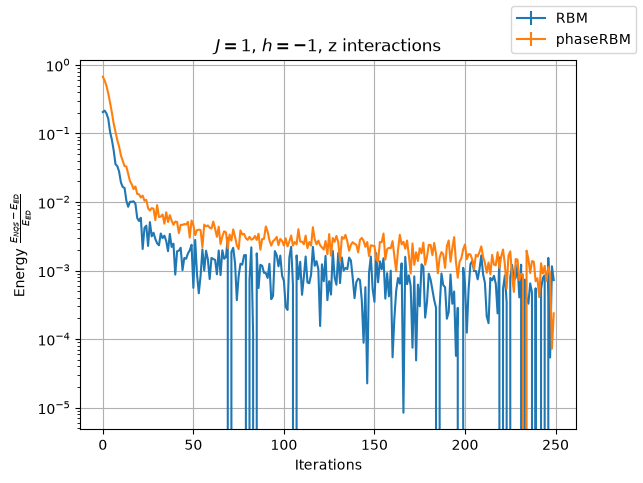

In [ ]:
N = 16
J = +1
h = -1
inter_dir = "z"
nqs_ising = NQS_ising(N, h, J, inter_dir, True)

n_iter = 250
learning_rate=0.04

fig, ax = plt.subplots()

model = myRBM(N=N, alpha=1, rngs=nnx.Rngs(2))
nqs_ising.optimization_loop(model, n_iter=n_iter, learning_rate=learning_rate)
nqs_ising.print()
# plt.errorbar(nqs_ising.iterations, nqs_ising.energies, yerr=nqs_ising.sigmas, label="RBM")
ax.errorbar(nqs_ising.iterations, nqs_ising.rel_errors, yerr=nqs_ising.sigmas*0, label="RBM")

model = phaseRBM(N=N, alpha=1, rngs=nnx.Rngs(2))
nqs_ising.optimization_loop(model, n_iter=n_iter, learning_rate=learning_rate)
nqs_ising.print()
# plt.errorbar(nqs_ising.iterations, nqs_ising.energies, yerr=nqs_ising.sigmas, label="phaseRBM")
ax.errorbar(nqs_ising.iterations, nqs_ising.rel_errors, yerr=nqs_ising.sigmas*0, label="phaseRBM")

# plt.hlines([nqs_ising.E_gs], xmin=0, xmax=n_iter-1, color="black", label=f"ED $E_{{gs}}$={nqs_ising.E_gs:.2f}")

fig.legend()
ax.set_xlabel("Iterations")
ax.set_ylabel(r"Relative Error $\left|\frac{E_{NQS}-E_{ED}}{E_{ED}}\right|$")
ax.set_title(f"$J={J}$, $h={h}$, {inter_dir} Interactions")
ax.set_yscale("log")
ax.grid()
fig.savefig("../plot/rbm-phaserbm-comparison-log.pdf")

### Fidelity Scan (ED)

n params: 168
(1,) (4096, 1)
0 0.1
n params: 168
(1,) (4096, 1)
1 0.15
n params: 168
(1,) (4096, 1)
2 0.2
n params: 168
(1,) (4096, 1)
3 0.25
n params: 168
(1,) (4096, 1)
4 0.3
n params: 168
(1,) (4096, 1)
5 0.35
n params: 168
(1,) (4096, 1)
6 0.39999999999999997
n params: 168
(1,) (4096, 1)
7 0.44999999999999996
n params: 168
(1,) (4096, 1)
8 0.5
n params: 168
(1,) (4096, 1)
9 0.5499999999999999
n params: 168
(1,) (4096, 1)
10 0.6
n params: 168
(1,) (4096, 1)
11 0.6499999999999999
n params: 168
(1,) (4096, 1)
12 0.7
n params: 168
(1,) (4096, 1)
13 0.75
n params: 168
(1,) (4096, 1)
14 0.7999999999999999
n params: 168
(1,) (4096, 1)
15 0.85
n params: 168
(1,) (4096, 1)
16 0.8999999999999999
n params: 168
(1,) (4096, 1)
17 0.95
n params: 168
(1,) (4096, 1)
18 0.9999999999999999
n params: 168
(1,) (4096, 1)
19 1.0499999999999998
n params: 168
(1,) (4096, 1)
20 1.0999999999999999
n params: 168
(1,) (4096, 1)
21 1.15
n params: 168
(1,) (4096, 1)
22 1.2
n params: 168
(1,) (4096, 1)
23 1.25
n

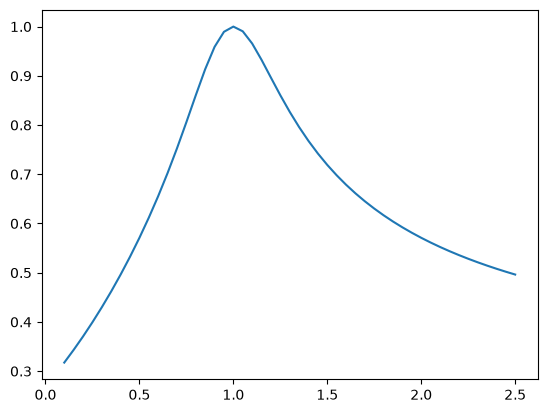

In [56]:
N = 12
model = myRBM(N=N, alpha=1, rngs=nnx.Rngs(2))

lbda = 1
J = 1
h = lbda*J
nqs_ising = NQS_ising(N, h, J, model, 'x', True)
_, target_state = nqs_ising.solve_exactly(compute_eigenvectors=True)
# print(target_state)
# infidelity_operator = nk.observable.InfidelityOperator(target_state=)

lbda_range_ed = jnp.linspace(0.1, 2.5, 49)
fidelities_ed = []
for i in range(len(lbda_range_ed)):
    lbda = lbda_range_ed[i]
    J = 1
    h = lbda*J
    print(i, lbda)

    nqs_ising = NQS_ising(N, h, J, model, 'x', True)
    _, ground_state = nqs_ising.solve_exactly(compute_eigenvectors=True)
    # fidelities_ed.append(1 - ground_state.expect(infidelity_operator).mean)
    fidelities_ed.append( (ground_state.T @ target_state)**2 )

plt.plot(lbda_range_ed, fidelities_ed)


### Fidelity Scan (NQS)

n params: 120


100%|██████████| 150/150 [00:05<00:00, 29.31it/s, Energy=-12.7895 ± 0.0067 [σ²=4.5e-02, R̂=1.004]]


0 0.0
n params: 120


100%|██████████| 150/150 [00:05<00:00, 28.52it/s, Energy=-9.9960 ± 0.0040 [σ²=1.6e-02, R̂=1.008]]                                


1 0.1
n params: 120


100%|██████████| 150/150 [00:06<00:00, 21.95it/s, Energy=-10.02457 ± 0.00048 [σ²=2.3e-04, R̂=1.017]]  


... (260 outputs left out)

24 2.4000000000000004
n params: 120


100%|██████████| 150/150 [00:07<00:00, 20.05it/s, Energy=-25.0475 ± 0.0063 [σ²=4.1e-02, R̂=1.012]]


25 2.5
n params: 120


100%|██████████| 150/150 [00:07<00:00, 20.64it/s, Energy=-26.0083 ± 0.0065 [σ²=4.2e-02, R̂=1.002]]


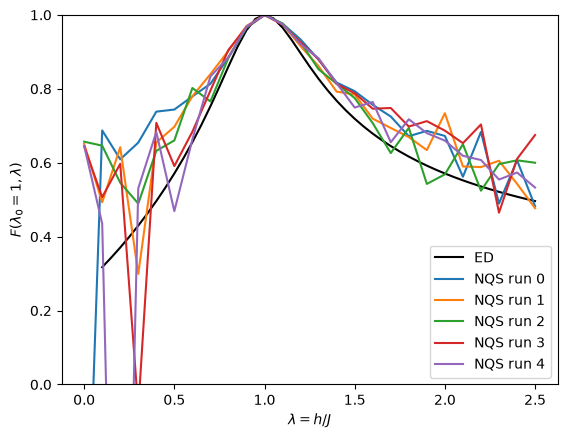

In [58]:
N = 10
model = myRBM(N=N, alpha=1, rngs=nnx.Rngs(2))

n_runs = 5
n_lbda = 26
# lbda_fidelities = np.zeros((n_runs+1, n_lbda))

plt.plot(lbda_range_ed, fidelities_ed, label="ED", color="black")

for j in range(n_runs):
    lbda0 = 1
    J = -1
    h = lbda0*J
    nqs_ising = NQS_ising(N, h, J, model, 'z', exact_solution=True)
    target_state = nqs_ising.optimization_loop(n_iter=150, learning_rate=0.03)
    # nqs_ising.plot()
    infidelity_operator = nk.observable.InfidelityOperator(target_state=target_state)

    lbda_range = jnp.linspace(0, 2.5, n_lbda)
    fidelities = []
    for i in range(n_lbda):
        lbda = lbda_range[i]
        J = -1
        h = lbda*J
        print(i, lbda)

        nqs_ising = NQS_ising(N, h, J, model, 'z', True)
        ground_state = nqs_ising.optimization_loop(n_iter=150, learning_rate=0.03)
        # nqs_ising.plot()
        fidelities.append(1 - ground_state.expect(infidelity_operator).mean) # actually infidelities

    plt.plot(lbda_range, fidelities, label=f"NQS run {j}")

plt.ylim(0, 1)
plt.xlabel(r"$\lambda = h/J$")
plt.ylabel(f"$F(\\lambda_0={lbda0}, \\lambda)$")
plt.legend()
plt.savefig("../plot/fidelities1.pdf")
plt.show()
